# CLIP: Contrastive Language–Image Pre-training

**Paper:** [Learning Transferable Visual Models From Natural Language Supervision](https://arxiv.org/abs/2103.00020)

**Authors:** Alec Radford, Jong Wook Kim, Chris Hallacy, et al. (OpenAI, 2021)

This notebook implements a simplified CLIP model from scratch: a dual image–text encoder trained with a contrastive (InfoNCE) loss on synthetic image–caption pairs, followed by a zero-shot classification demo.

## 1. Setup & Imports

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
import random
import math
from sklearn.manifold import TSNE

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')

Device: cuda
GPU: Tesla T4


## 2. Synthetic Dataset — Colored Shapes

We create a dataset of simple geometric images (circles, squares, triangles) in various colors, each paired with a text caption like "a red circle". This serves as a stand-in for the 400M (image, text) pairs used in the original paper.

Train: 800 pairs, Test: 200 pairs


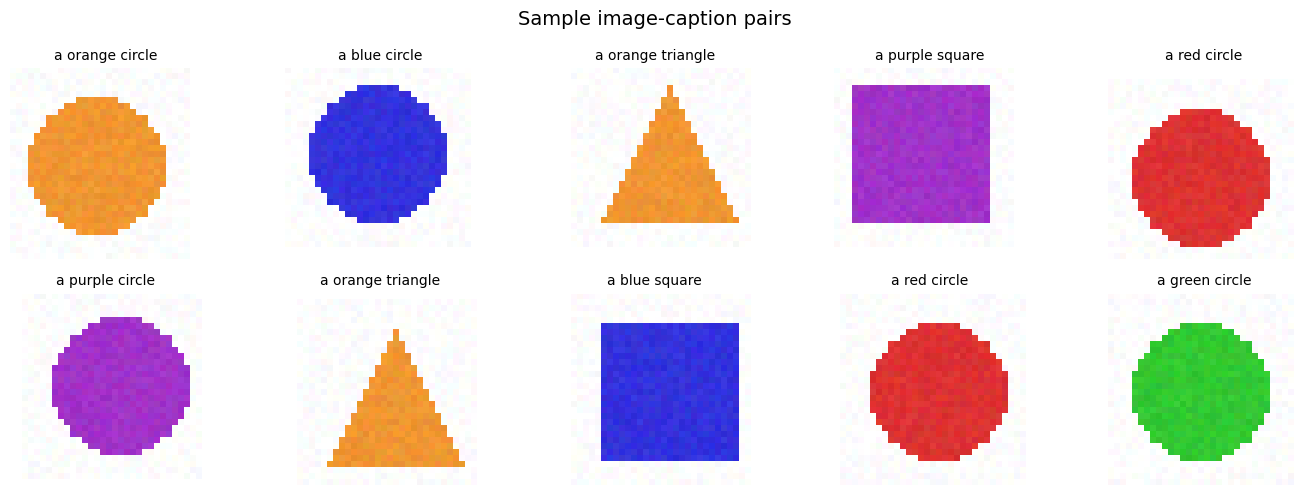

In [2]:
from PIL import Image, ImageDraw

COLORS = ['red', 'blue', 'green', 'yellow', 'purple', 'orange']
SHAPES = ['circle', 'square', 'triangle']

COLOR_RGB = {
    'red': (220, 50, 50), 'blue': (50, 50, 220), 'green': (50, 200, 50),
    'yellow': (220, 220, 50), 'purple': (160, 50, 200), 'orange': (240, 150, 50)
}
IMG_SIZE = 32

def draw_shape(shape, color, size=IMG_SIZE):
    img = Image.new('RGB', (size, size), (255, 255, 255))
    draw = ImageDraw.Draw(img)
    c = COLOR_RGB[color]
    m = size // 6
    if shape == 'circle':
        draw.ellipse([m, m, size-m, size-m], fill=c)
    elif shape == 'square':
        draw.rectangle([m, m, size-m, size-m], fill=c)
    elif shape == 'triangle':
        draw.polygon([(size//2, m), (m, size-m), (size-m, size-m)], fill=c)
    return img

def add_jitter(img, max_shift=2, noise_level=10):
    arr = np.array(img).astype(np.int16)
    noise = np.random.randint(-noise_level, noise_level+1, arr.shape)
    arr = np.clip(arr + noise, 0, 255).astype(np.uint8)
    img = Image.fromarray(arr)
    dx, dy = random.randint(-max_shift, max_shift), random.randint(-max_shift, max_shift)
    bg = Image.new('RGB', (IMG_SIZE, IMG_SIZE), (255, 255, 255))
    bg.paste(img, (dx, dy))
    return bg

class ShapeDataset(Dataset):
    def __init__(self, n_samples=800, jitter=True):
        self.samples = []
        for _ in range(n_samples):
            color = random.choice(COLORS)
            shape = random.choice(SHAPES)
            img = draw_shape(shape, color)
            if jitter:
                img = add_jitter(img)
            img_tensor = torch.tensor(np.array(img), dtype=torch.float32).permute(2,0,1) / 255.0
            caption = f'a {color} {shape}'
            self.samples.append((img_tensor, caption, f'{color}_{shape}'))
    def __len__(self): return len(self.samples)
    def __getitem__(self, idx): return self.samples[idx]

train_dataset = ShapeDataset(n_samples=800, jitter=True)
test_dataset = ShapeDataset(n_samples=200, jitter=True)
print(f'Train: {len(train_dataset)} pairs, Test: {len(test_dataset)} pairs')

fig, axes = plt.subplots(2, 5, figsize=(14, 5))
for i, ax in enumerate(axes.flat):
    img, caption, _ = train_dataset[i]
    ax.imshow(img.permute(1,2,0).numpy())
    ax.set_title(caption, fontsize=10)
    ax.axis('off')
plt.suptitle('Sample image-caption pairs', fontsize=14)
plt.tight_layout()
plt.show()

## 3. Character-Level Tokenizer

A simple character-level tokenizer that maps each character to an integer ID. This is a deliberate simplification — the real CLIP uses byte-pair encoding (BPE) with a 49K vocabulary.

In [3]:
class CharTokenizer:
    def __init__(self):
        self.char2idx = {}
        self.idx2char = {}
        self.vocab_size = 0
    def build_vocab(self, texts):
        chars = set()
        for t in texts:
            chars.update(t)
        chars = sorted(chars)
        self.char2idx = {c: i+1 for i, c in enumerate(chars)}
        self.idx2char = {i+1: c for i, c in enumerate(chars)}
        self.vocab_size = len(chars) + 1
        print(f'Vocabulary size: {self.vocab_size}')
    def encode(self, text, max_len=20):
        ids = [self.char2idx.get(c, 0) for c in text]
        if len(ids) < max_len:
            ids = ids + [0]*(max_len-len(ids))
        else:
            ids = ids[:max_len]
        return ids

all_captions = [s[1] for s in train_dataset.samples] + [s[1] for s in test_dataset.samples]
tokenizer = CharTokenizer()
tokenizer.build_vocab(all_captions)
MAX_LEN = 20

def collate_fn(batch):
    imgs = torch.stack([b[0] for b in batch])
    captions = [b[1] for b in batch]
    labels = [b[2] for b in batch]
    tokenized = torch.tensor([tokenizer.encode(c, MAX_LEN) for c in captions], dtype=torch.long)
    return imgs, tokenized, captions, labels

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, collate_fn=collate_fn, drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, collate_fn=collate_fn)
print(f'Train batches: {len(train_loader)}, Test batches: {len(test_loader)}')

Vocabulary size: 20
Train batches: 12, Test batches: 4


## 4. Image Encoder

An MLP-based image encoder that flattens the image and projects to the shared embedding space. The real CLIP uses ResNet-50 or a Vision Transformer, but for this toy dataset of simple shapes, an MLP suffices to demonstrate the concept.

In [4]:
class ImageEncoder(nn.Module):
    def __init__(self, embed_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3 * IMG_SIZE * IMG_SIZE, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, embed_dim)
        )
    def forward(self, x):
        x = x.flatten(1)
        return self.net(x)

image_encoder = ImageEncoder(embed_dim=128).to(device)
print(f'Image encoder parameters: {sum(p.numel() for p in image_encoder.parameters()):,}')

Image encoder parameters: 1,737,600


## 5. Text Encoder

A GRU-based text encoder with character-level token embeddings. The final hidden state is projected to the shared embedding space. The real CLIP uses a 12-layer Transformer, but a GRU suffices for our short captions.

In [5]:
class TextEncoder(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=128, max_len=20):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, hidden_dim)
        self.rnn = nn.GRU(hidden_dim, hidden_dim, batch_first=True, num_layers=1)
        self.projection = nn.Linear(hidden_dim, embed_dim)
    def forward(self, x):
        embeddings = self.token_embedding(x)
        _, hidden = self.rnn(embeddings)
        return self.projection(hidden.squeeze(0))

text_encoder = TextEncoder(vocab_size=tokenizer.vocab_size, embed_dim=128, max_len=MAX_LEN).to(device)
print(f'Text encoder parameters: {sum(p.numel() for p in text_encoder.parameters()):,}')

Text encoder parameters: 118,144


## 6. CLIP Model

Combines both encoders and computes the cosine similarity matrix with a learnable temperature parameter. The temperature is initialized to `log(1/0.07)` ≈ 2.659, matching the paper.

In [6]:
class CLIPModel(nn.Module):
    def __init__(self, image_encoder, text_encoder, embed_dim=128):
        super().__init__()
        self.image_encoder = image_encoder
        self.text_encoder = text_encoder
        self.logit_scale = nn.Parameter(torch.ones([]) * math.log(1 / 0.07))
    def forward(self, images, tokenized_captions):
        image_features = F.normalize(self.image_encoder(images), dim=-1)
        text_features = F.normalize(self.text_encoder(tokenized_captions), dim=-1)
        logit_scale = self.logit_scale.exp().clamp(max=100.0)
        logits_per_image = logit_scale * image_features @ text_features.t()
        logits_per_text = logits_per_image.t()
        return logits_per_image, logits_per_text

clip_model = CLIPModel(image_encoder, text_encoder, embed_dim=128).to(device)
print(f'Total CLIP parameters: {sum(p.numel() for p in clip_model.parameters()):,}')
print(f'Initial temperature: {clip_model.logit_scale.exp().item():.4f}')

Total CLIP parameters: 1,855,745
Initial temperature: 14.2857


## 7. Contrastive Loss (Symmetric InfoNCE)

The loss treats the similarity matrix as a classification problem: for each image, the correct caption should have the highest similarity (row-wise softmax), and vice versa (column-wise softmax). The two losses are averaged.

In [7]:
def contrastive_loss(logits_per_image, logits_per_text):
    batch_size = logits_per_image.size(0)
    labels = torch.arange(batch_size, device=logits_per_image.device)
    loss_image = F.cross_entropy(logits_per_image, labels)
    loss_text = F.cross_entropy(logits_per_text, labels)
    return (loss_image + loss_text) / 2

dummy = torch.randn(4, 4)
print(f'Sanity check loss (should be ~ln(4)={math.log(4):.3f}): {contrastive_loss(dummy, dummy.t()):.3f}')

Sanity check loss (should be ~ln(4)=1.386): 1.929


## 8. Training Loop

Train for 20 epochs with Adam optimizer. The loss should steadily decrease as the model learns to align matching image–text pairs.

In [8]:
EPOCHS = 20
LR = 1e-3
optimizer = optim.Adam(clip_model.parameters(), lr=LR)
loss_history = []

clip_model.train()
for epoch in range(EPOCHS):
    epoch_loss = 0.0
    n_batches = 0
    for images, tokenized, captions, labels in train_loader:
        images, tokenized = images.to(device), tokenized.to(device)
        optimizer.zero_grad()
        logits_i, logits_t = clip_model(images, tokenized)
        loss = contrastive_loss(logits_i, logits_t)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
        n_batches += 1
    avg_loss = epoch_loss / n_batches
    loss_history.append(avg_loss)
    if (epoch+1) % 4 == 0 or epoch == 0:
        print(f'Epoch {epoch+1:3d}/{EPOCHS} | Loss: {avg_loss:.4f} | Temp: {clip_model.logit_scale.exp().item():.3f}')

print(f'\nTraining complete. Final loss: {loss_history[-1]:.4f}')

Epoch   1/20 | Loss: 4.1096 | Temp: 14.244
Epoch   4/20 | Loss: 3.3684 | Temp: 14.309


Epoch   8/20 | Loss: 2.9064 | Temp: 14.714


Epoch  12/20 | Loss: 2.0173 | Temp: 15.289


Epoch  16/20 | Loss: 1.7857 | Temp: 15.732


Epoch  20/20 | Loss: 1.4464 | Temp: 16.267

Training complete. Final loss: 1.4464


## 9. Training Visualization

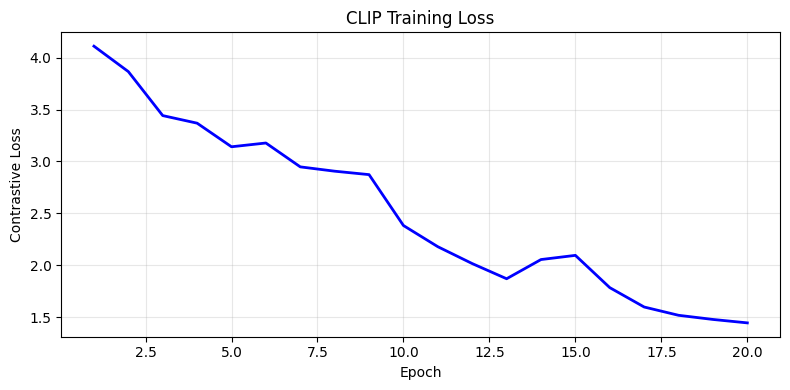

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCHS+1), loss_history, 'b-', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Contrastive Loss')
plt.title('CLIP Training Loss')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Zero-Shot Classification

After training, we classify images by encoding text prompts for each class and finding the closest match. This is the key capability of CLIP — no task-specific training needed.

In [10]:
def zero_shot_classify(model, images, class_prompts, tokenizer, device, max_len=20):
    model.eval()
    with torch.no_grad():
        tokenized_prompts = torch.tensor(
            [tokenizer.encode(p, max_len) for p in class_prompts], dtype=torch.long
        ).to(device)
        text_features = F.normalize(model.text_encoder(tokenized_prompts), dim=-1)
        image_features = F.normalize(model.image_encoder(images.to(device)), dim=-1)
        similarity = (image_features @ text_features.t()).cpu().numpy()
    return similarity

class_prompts = [f'a {c} {s}' for c in COLORS for s in SHAPES]
class_names = [f'{c}_{s}' for c in COLORS for s in SHAPES]
print(f'Class prompts ({len(class_prompts)}):')
for i, p in enumerate(class_prompts):
    print(f'  {i}: {p}')

all_images = []
all_labels = []
for images, _, _, labels in test_loader:
    all_images.append(images)
    all_labels.extend(labels)
all_images = torch.cat(all_images, dim=0)

all_preds = []
for i in range(0, len(all_images), 100):
    sim = zero_shot_classify(clip_model, all_images[i:i+100], class_prompts, tokenizer, device)
    all_preds.extend(sim.argmax(axis=1))

all_preds = np.array(all_preds)
true_labels = np.array([class_names.index(l) for l in all_labels])
accuracy = (all_preds == true_labels).mean()
print(f'\nZero-shot classification accuracy: {accuracy:.2%} ({(all_preds == true_labels).sum()}/{len(true_labels)})')

Class prompts (18):
  0: a red circle
  1: a red square
  2: a red triangle
  3: a blue circle
  4: a blue square
  5: a blue triangle
  6: a green circle
  7: a green square
  8: a green triangle
  9: a yellow circle
  10: a yellow square
  11: a yellow triangle
  12: a purple circle
  13: a purple square
  14: a purple triangle
  15: a orange circle
  16: a orange square
  17: a orange triangle

Zero-shot classification accuracy: 100.00% (200/200)


### Visualize Zero-Shot Predictions

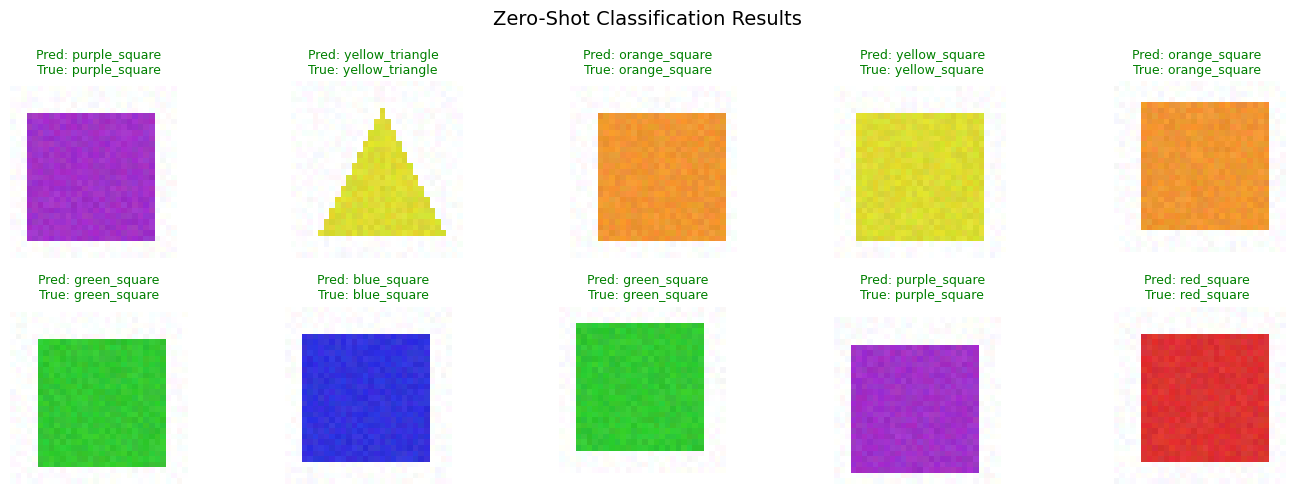

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(14, 5))
for i, ax in enumerate(axes.flat):
    idx = random.randint(0, len(all_images)-1)
    img = all_images[idx].permute(1,2,0).numpy()
    pred = class_names[all_preds[idx]]
    true = all_labels[idx]
    ax.imshow(img)
    ax.set_title(f'Pred: {pred}\nTrue: {true}', fontsize=9,
                 color='green' if pred == true else 'red')
    ax.axis('off')
plt.suptitle('Zero-Shot Classification Results', fontsize=14)
plt.tight_layout()
plt.show()

## 11. Embedding Space Visualization (t-SNE)

Project the learned 128-dim image embeddings to 2D using t-SNE to see if the model has learned semantically meaningful clusters.

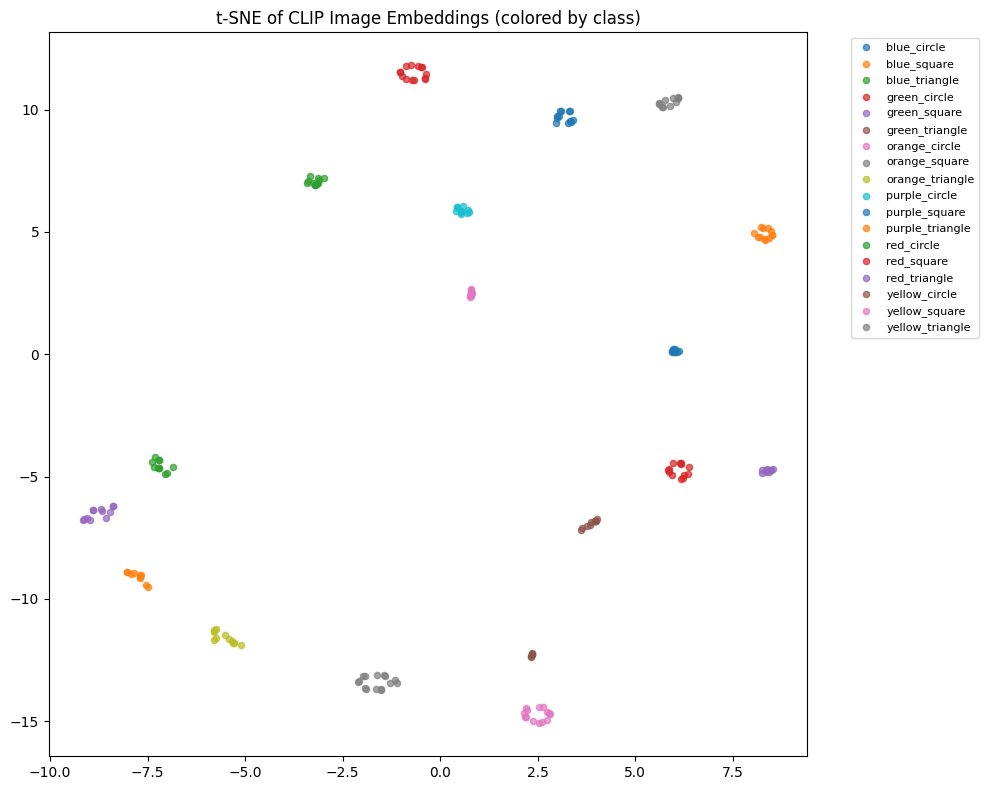

In [12]:
clip_model.eval()
with torch.no_grad():
    all_features = []
    for i in range(0, len(all_images), 100):
        batch = all_images[i:i+100].to(device)
        features = F.normalize(clip_model.image_encoder(batch), dim=-1)
        all_features.append(features.cpu().numpy())
all_features = np.concatenate(all_features, axis=0)

tsne = TSNE(n_components=2, random_state=42, perplexity=25)
embeddings_2d = tsne.fit_transform(all_features)

plt.figure(figsize=(10, 8))
for label in sorted(set(all_labels)):
    mask = np.array([l == label for l in all_labels])
    plt.scatter(embeddings_2d[mask, 0], embeddings_2d[mask, 1], label=label, s=20, alpha=0.7)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.title('t-SNE of CLIP Image Embeddings (colored by class)')
plt.tight_layout()
plt.show()

## 12. Similarity Heatmap

Visualize the image–text similarity matrix for a batch of test samples. The diagonal should be bright (high similarity for matching pairs).

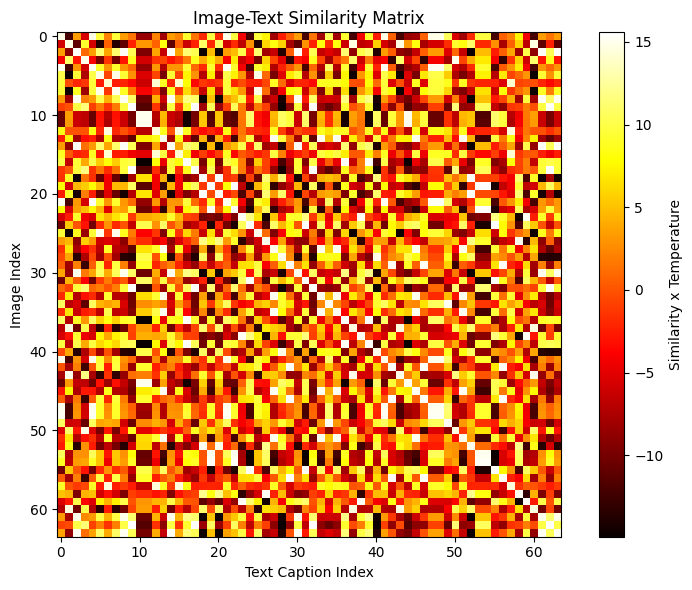

Sample predictions (image -> best matching text):
  Image 0 ( a green circle) ->  a green circle [OK]
  Image 1 (a purple triangle) -> a purple triangle [OK]
  Image 2 (a yellow square) -> a yellow square [OK]
  Image 3 (a orange triangle) -> a orange triangle [OK]
  Image 4 ( a green circle) ->  a green circle [WRONG]
  Image 5 ( a green square) ->  a green square [OK]
  Image 6 (a orange circle) -> a orange circle [OK]
  Image 7 ( a green square) ->  a green square [WRONG]


In [13]:
batch_imgs, batch_tokens, batch_caps, batch_labels = next(iter(test_loader))
clip_model.eval()
with torch.no_grad():
    logits_i, _ = clip_model(batch_imgs.to(device), batch_tokens.to(device))
    sim_matrix = logits_i.cpu().numpy()

plt.figure(figsize=(8, 6))
plt.imshow(sim_matrix, cmap='hot', interpolation='nearest')
plt.colorbar(label='Similarity x Temperature')
plt.xlabel('Text Caption Index')
plt.ylabel('Image Index')
plt.title('Image-Text Similarity Matrix')
plt.tight_layout()
plt.show()

print('Sample predictions (image -> best matching text):')
for i in range(min(8, sim_matrix.shape[0])):
    best = sim_matrix[i].argmax()
    ok = 'OK' if best == i else 'WRONG'
    print(f'  Image {i} ({batch_caps[i]:>15s}) -> {batch_caps[best]:>15s} [{ok}]')

## Summary

This notebook demonstrated the core CLIP architecture:

1. **Dual encoder** — separate image (MLP) and text (GRU) encoders projecting to a shared 128-dim embedding space
2. **Contrastive loss** — symmetric InfoNCE loss aligning matching image–text pairs while pushing mismatched pairs apart
3. **Learnable temperature** — controls the sharpness of the softmax in the contrastive loss
4. **Zero-shot classification** — classify images by computing similarity to text prompts, without any task-specific training
5. **Embedding visualization** — t-SNE shows that CLIP learns semantically meaningful clusters

The real CLIP scales this to 400M (image, text) pairs with ResNet-50/ViT image encoders and a 12-layer Transformer text encoder, achieving remarkable zero-shot transfer across 30+ benchmarks.

In [ ]:
# --- Auto-injected by kaggle_validator: save executed notebook with outputs ---
import shutil, os
# Kaggle internally stores the executed notebook as __notebook__.ipynb
if os.path.exists('/kaggle/working/__notebook__.ipynb'):
    shutil.copy('/kaggle/working/__notebook__.ipynb', '/kaggle/working/executed_solution.ipynb')
    print('Executed notebook saved to output folder.')
else:
    # Fallback: try alternative path
    import glob
    candidates = glob.glob('/kaggle/working/*.ipynb')
    print(f'Available notebooks in output: {candidates}')
